In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')

print("Imports successful")
csv = pd.read_csv('chess_rating_plateau.csv')
print("Read CSV successful")

Imports successful
Read CSV successful


In [2]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, PrecisionRecallDisplay

drop = ["player_id", "peak_rating", "plateaued", "reached_expert", "deliberate_hours", "age_now"]
features = [c for c in csv.columns if c not in drop]
X = csv[features]

def get_tree(target):
    y = csv[target]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

    grid = GridSearchCV(
        DecisionTreeClassifier(random_state=42), #, class_weight="balanced"),
        {"max_depth": range(2, 10), "min_samples_leaf": [5, 10, 25, 50]},
        cv=5, scoring="f1")
    grid.fit(X_train, y_train)
    best = grid.best_estimator_

    print(grid.best_params_)
    print(classification_report(y_test, best.predict(X_test)))
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    ConfusionMatrixDisplay.from_estimator(best, X_test, y_test, ax=ax[0])
    ax[0].grid(False)
    ax[0].set_title("Confusion Matrix")
    PrecisionRecallDisplay.from_estimator(best, X_test, y_test, ax=ax[1])
    ax[1].set_title("Precision Recall Curve")
    plt.show()

    print(pd.Series(best.feature_importances_, index=features).sort_values(ascending=False))
    return best

{'max_depth': 9, 'min_samples_leaf': 25}
              precision    recall  f1-score   support

           0       0.91      0.94      0.93      7200
           1       0.72      0.64      0.68      1800

    accuracy                           0.88      9000
   macro avg       0.82      0.79      0.80      9000
weighted avg       0.87      0.88      0.88      9000



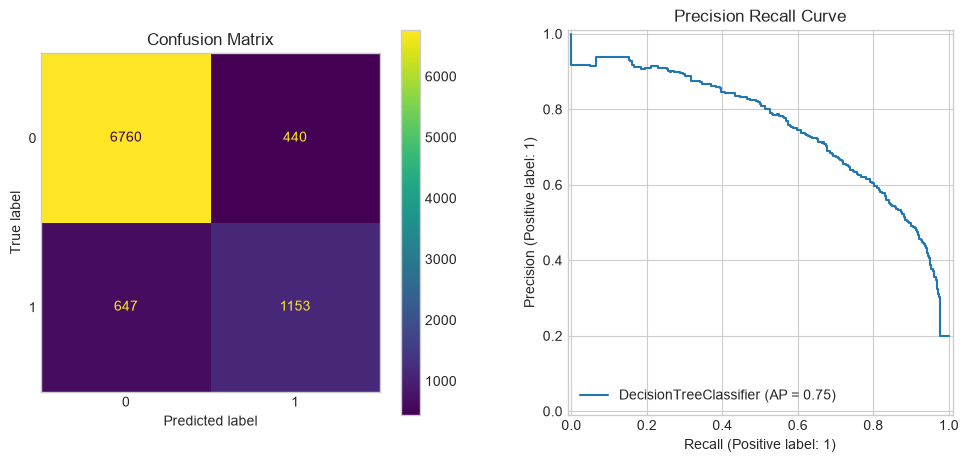

games_played              0.269525
cognitive_ability         0.252705
tactics_training_hours    0.201043
deliberate_share          0.120941
starting_age              0.090770
analyzes_own_games        0.046971
total_study_hours         0.013467
years_playing             0.002339
opening_study_hours       0.001376
has_coach                 0.000841
studies_endgames          0.000022
dtype: float64


In [3]:
expert_tree = get_tree("reached_expert")

{'max_depth': 6, 'min_samples_leaf': 50}
              precision    recall  f1-score   support

           0       0.66      0.83      0.73      5505
           1       0.55      0.33      0.41      3495

    accuracy                           0.63      9000
   macro avg       0.60      0.58      0.57      9000
weighted avg       0.62      0.63      0.61      9000



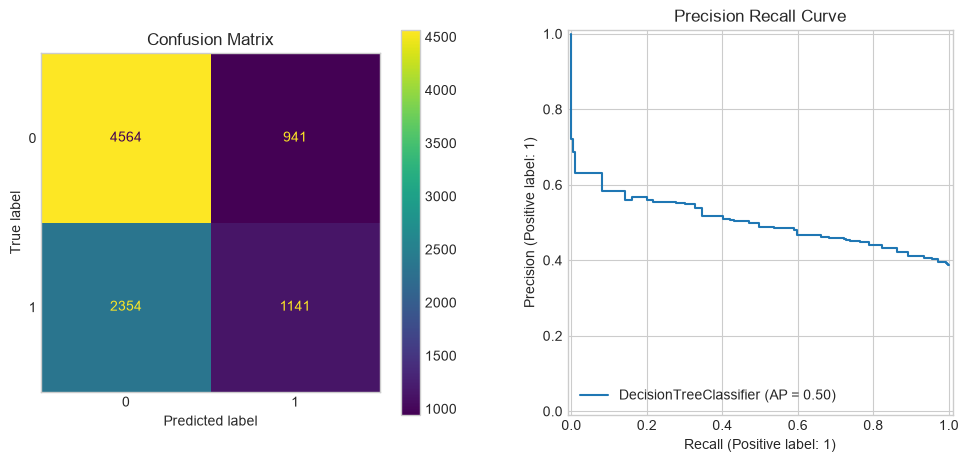

deliberate_share          0.425767
games_played              0.290910
years_playing             0.158561
analyzes_own_games        0.104860
cognitive_ability         0.005825
opening_study_hours       0.004521
starting_age              0.004192
total_study_hours         0.002720
has_coach                 0.001661
studies_endgames          0.000983
tactics_training_hours    0.000000
dtype: float64


In [4]:
plateaued_tree = get_tree("plateaued")

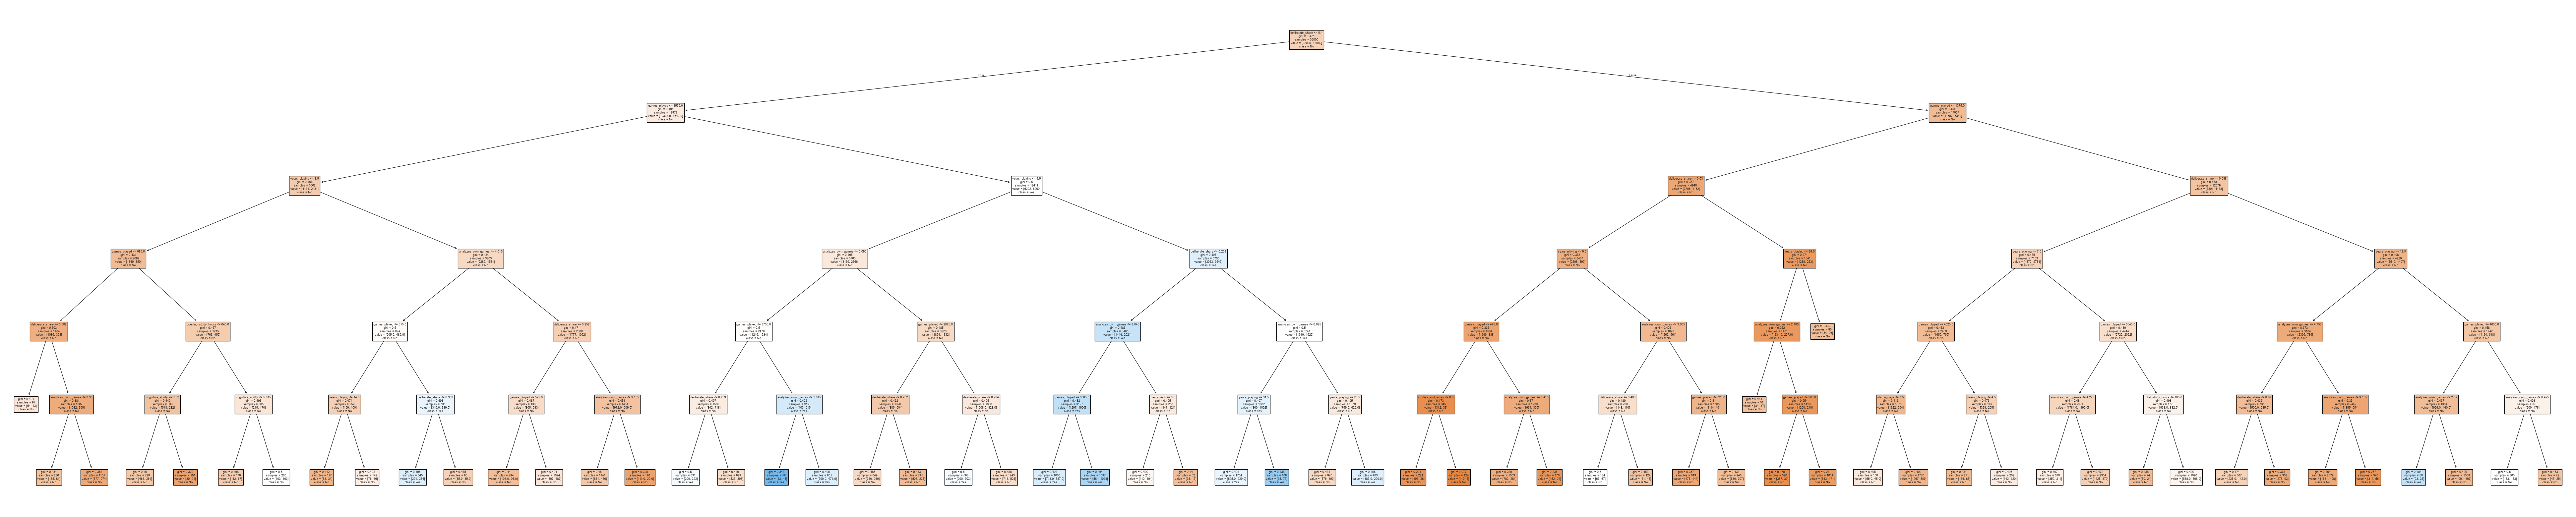

In [5]:
plt.figure(figsize=(100, 20))
plot_tree(plateaued_tree, feature_names=features, class_names=["No", "Yes"], filled=True)
plt.savefig("plateaued_tree.png")
plt.show()

In [6]:
plt.figure(figsize=(450, 60))
plot_tree(expert_tree, feature_names=features, class_names=["No", "Yes"], filled=True)
plt.savefig("tree.png")
# plt.show()